#### Setup

In [1]:
#import all necessary extensions
import numpy as np, pandas as pd, scipy.sparse as sp, time
from sklearn.decomposition import TruncatedSVD, PCA
from sklearn.preprocessing import normalize
import matplotlib.pyplot as plt

In [2]:
#reading the file
filename = "data/raw/online_retail_II.xlsx"
sheets = pd.read_excel(filename, sheet_name=None)


#### Helper functions

In [3]:
#creating small helper function to print removed rows after each cleaning
cleaning_log = []

def log_removed_rows(rule, df_before_change, df_after_change):
      removed = len(df_before_change) - len(df_after_change)
      print(rule, "Rows removed:", removed, "| New data size:", len(df_after_change))
      cleaning_log.append({"rule": rule, "rows_removed": removed,
                           "rows_left": len(df_after_change)})
      return df_after_change

### Data Exploration

#### DE1

In [4]:
#uniting two sheets into one dataframe
df = pd.concat(sheets.values(), ignore_index = True)

In [5]:
#looking at first five rows of the file
df.head(10)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
5,489434,22064,PINK DOUGHNUT TRINKET POT,24,2009-12-01 07:45:00,1.65,13085.0,United Kingdom
6,489434,21871,SAVE THE PLANET MUG,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom
7,489434,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,2009-12-01 07:45:00,5.95,13085.0,United Kingdom
8,489435,22350,CAT BOWL,12,2009-12-01 07:46:00,2.55,13085.0,United Kingdom
9,489435,22349,"DOG BOWL , CHASING BALL DESIGN",12,2009-12-01 07:46:00,3.75,13085.0,United Kingdom


In [6]:
#length of the data frame (must be > million)
len(df)

1067371

In [7]:
#checking types and names of columns
df.dtypes

Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
Price                 float64
Customer ID           float64
Country                   str
dtype: object

Customer ID is type float64, but it must be a whole number. Potentially happens because missing customer IDs are Nan which is float, therefore, the whole column must be float. We will fix it after handling missing values.

In [8]:
#how many missing values we have per column
print(df.isna().sum())

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64


In [9]:
#want to see percentage of missing values for every column
print(df.isna().mean()*100)

Invoice         0.000000
StockCode       0.000000
Description     0.410541
Quantity        0.000000
InvoiceDate     0.000000
Price           0.000000
Customer ID    22.766873
Country         0.000000
dtype: float64


The dataset looks good for missing values besides Description and CustomerID field. Customer ID misses are 22.8% of the whole dataset - potentially all of it can be dropped. Then possibly Description will have less missing values as well.

#### DE2

First, we will deal with cancellations. By project rules the invoices that start from C are cancelled and should not be in our data.

In [10]:
print("DF before removing cancellations: ", len(df))

df_no_cancellations = df[~df["Invoice"].astype(str).str.startswith('C')]

df = log_removed_rows("Cancellations.", df, df_no_cancellations)

DF before removing cancellations:  1067371
Cancellations. Rows removed: 19494 | New data size: 1047877



Non-positive values for quantity and price will be removed because they are returns, adjustments or free items rather than real purchases, so keeping them would distort what customers actually bought.

In [11]:
#check for non-positive quantity or price
df[["Quantity", "Price"]].le(0).any()

Quantity    True
Price       True
dtype: bool

In [12]:
df_cleaned = df[(df['Price'] > 0) & (df['Quantity'] > 0)]

df = log_removed_rows("Non-positive price or quantity.", df, df_cleaned)

Non-positive price or quantity. Rows removed: 6207 | New data size: 1041670


Next we will clean our dataframe from non-product codes. We are going to leave only the ones that follow a format of 5 digits with optional letter. All others are non-product codes and should not be in our dataframe.

In [13]:
#defining the regex pattern (5 digits, followed by optional letters)
pattern = r'^\d{5}[a-zA-Z]*$'

#filtering the DataFrame to keep only matching rows
df_filtered = df[df['StockCode'].astype(str).str.match(pattern, na=False)]

df = log_removed_rows("Product codes left only.", df, df_filtered)

Product codes left only. Rows removed: 4794 | New data size: 1036876


Next, we will be dropping rows with empty CustomerID's. Every row has to go into a customer x product matrix and a row without CustomerID has no customer to belong to, therefore, useless for our purpose.

In [14]:
df_cleaned = df[df['Customer ID'].notna()]

df = log_removed_rows("Left non-empty CustomerID rows.", df, df_cleaned)

df['Customer ID'] = df['Customer ID'].astype(int) # bring ID's back to whole numbers

Left non-empty CustomerID rows. Rows removed: 234244 | New data size: 802632


In [15]:
pd.DataFrame(cleaning_log)

,rule,rows_removed,rows_left
0,Cancellations.,19494,1047877
1,Non-positive price or quantity.,6207,1041670
2,Product codes left only.,4794,1036876
3,Left non-empty CustomerID rows.,234244,802632


#### DE3

In [16]:
latest_date = df["InvoiceDate"].max()
cutoff_date = latest_date - pd.DateOffset(months=2)
print(cutoff_date, " - ", latest_date)

2011-10-09 12:50:00  -  2011-12-09 12:50:00


In [17]:
train = df[df["InvoiceDate"] < cutoff_date]
test  = df[df["InvoiceDate"] >= cutoff_date]

print("Train rows:", len(train), "| Test rows:", len(test))
print("Train:", train["InvoiceDate"].min(), "to", train["InvoiceDate"].max())
print("Test: ", test["InvoiceDate"].min(), "to", test["InvoiceDate"].max())

Train rows: 684069 | Test rows: 118563
Train: 2009-12-01 07:45:00 to 2011-10-09 12:49:00
Test:  2011-10-09 12:59:00 to 2011-12-09 12:50:00


We kept only test customers who also appear in training, because the model cannot recommend anything to a customer it has never seen, and only products they never bought before, so the evaluation measures
  whether the model can suggest something new rather than just repeat a customer's past purchases.

In [18]:
pair = ["Customer ID", "StockCode"]
  
#every (customer, product) pair seen in training
seen = train[pair].drop_duplicates()

#test pairs only for customers who also appear in training
test_pairs = test[pair].drop_duplicates()
test_pairs = test_pairs[test_pairs["Customer ID"].isin(train["Customer ID"])]

#keep the test pairs that are not in seen
merged = test_pairs.merge(seen, on=pair, how="left", indicator=True)
test_new = merged[merged["_merge"] == "left_only"].drop(columns="_merge")

print("Held-out pairs:", len(test_new), "| Test customers:", test_new["Customer ID"].nunique())

Held-out pairs: 49423 | Test customers: 1930


In [19]:
#saving train and held-out test files for the next steps
train.to_csv("data/processed/train.csv", index=False)
test_new.to_csv("data/processed/test_new.csv", index=False)
print("Saved:", len(train), "train rows,", len(test_new), "test pairs")

Saved: 684069 train rows, 49423 test pairs


#### DE4

In [37]:
train_pairs = train.groupby(pair, as_index=False)["Quantity"].sum()

#number of different customers per product 
customers_per_product = train_pairs["StockCode"].value_counts()
popular_products = customers_per_product[customers_per_product >= 10].index

before = len(train_pairs)
train_pairs = train_pairs[train_pairs["StockCode"].isin(popular_products)]
print("Pairs removed by product filter:", before - len(train_pairs))

# DE4: sparse customer x product matrix from TRAINING rows only
cust = {c: i for i, c in enumerate(train_pairs["Customer ID"].unique())}
prod = {p: j for j, p in enumerate(train_pairs["StockCode"].unique())}
rows = train_pairs["Customer ID"].map(cust)
cols = train_pairs["StockCode"].map(prod)
vals = np.log1p(train_pairs["Quantity"]) 
A = sp.csr_matrix((vals, (rows, cols)), shape=(len(cust), len(prod)))
print(A.shape, A.nnz, f"sparsity {1 - A.nnz / (A.shape[0] * A.shape[1]):.2%}")
print("Pairs before filter:", before)            # unique customer-product pairs before dropping rare productss

Pairs removed by product filter: 3792
(5473, 3687) 413927 sparsity 97.95%
Pairs before filter: 417719


We will keep only products bought by at least 10 different customers, because a product with only one or two buyers gives the model too little evidence to find similar products, so its similarity scores would be mostly noise. By doing so we will remove only 3,792 of 417,719 purchases so we lose very little data. The trade-off is that the dropped products can never be recommended, so a test purchase of one of them can never be a hit.


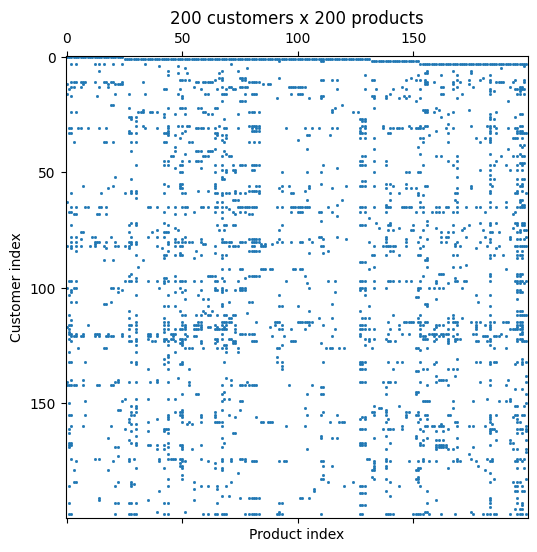

In [21]:
#each dot is a filled cell: a customer (row) bought a product (column)
plt.figure(figsize=(6, 6))
plt.spy(A[:200, :200], markersize=1)
plt.title("200 customers x 200 products")
plt.xlabel("Product index")
plt.ylabel("Customer index")
plt.show()

Output for DE4 section

In [22]:
sp.save_npz("data/processed/A_train.npz", A) # save the sparse matrix in scipy's own format
pd.Series(cust, name="row").rename_axis("Customer ID").to_csv("data/processed/customer_index.csv")  # Customer ID -> row number in A
pd.Series(prod, name="col").rename_axis("StockCode").to_csv("data/processed/product_index.csv")     # StockCode -> column number in A

#### DE5

In [24]:
#matrix report (DE5): size, sparsity and memory, dense vs sparse
n_customers, n_products = A.shape                      # rows = customers, columns = products
total_cells = n_customers * n_products                 # every cell, filled or empty
filled = A.nnz / total_cells                           # share of cells that are not zero

matrix_report = pd.Series({                            # Series = one column of named values
      "Customers (Rows)": n_customers,                   # how many customers
      "Products (Columns)": n_products,                  # how many products
      "Total Cells": total_cells,                        # size if we stored everything
      "Non-Zero Cells": A.nnz,                           # cells that hold a purchase
      "Sparsity %": round((1 - filled) * 100, 2),        # share of empty cells
      "Dense Memory (MB)": round(total_cells * 8 / 1e6, 1),        # 8 bytes for every cell
      "Sparse Memory (MB)": round((A.data.nbytes + A.indices.nbytes + A.indptr.nbytes) / 1e6, 1),  # only what CSR actually stores
}, dtype = object)
matrix_report   


Customers (Rows)          5473
Products (Columns)        3687
Total Cells           20178951
Non-Zero Cells          413927
Sparsity %               97.95
Dense Memory (MB)        161.4
Sparse Memory (MB)         5.0
dtype: object

### ML Tasks

#### ML1

We chose Truncated SVD as our main method because our matrix is 97.95% empty and SVD works directly on the sparse matrix without filling it in, and because one fit gives us both customer factors and product factors (a short list of theme scores for every customer and every product), so we can find similar products for ML3 straight from the product factors. Truncated because we will only keep top k themes which have the biggest values, so the data is compressed from 3,687 columns to k numbers per customer and product

#### ML2


In [25]:
# ML2: Truncated SVD on the sparse matrix (no centring)
t = time.time()
svd = TruncatedSVD(n_components=50, random_state=42).fit(A)
print("fit seconds", time.time() - t)
P_vec = normalize(svd.components_.T) # one row per product, length 1

fit seconds 0.13041210174560547


Since fit takes only 0.13 seconds we can conclude that 'too slow' is not an issue anymore.

In [29]:
results = []                                                       # one entry per k

for k in [10, 20, 50, 100, 200]:
    t = time.time()                                                # start the timer
    svd = TruncatedSVD(n_components=k, random_state=42).fit(A)
    fit_seconds = time.time() - t                                  # stop the timer: fit time only
    A_k = svd.inverse_transform(svd.transform(A))
    error = np.linalg.norm(A.toarray() - A_k) / sp.linalg.norm(A)
    results.append({"k": k, "fit_seconds": round(fit_seconds, 2), "error": round(error, 3)})

results = pd.DataFrame(results)                                    # list -> table
results

,k,fit_seconds,error
0,10,0.06,0.876
1,20,0.04,0.846
2,50,0.07,0.790
3,100,0.14,0.728
4,200,0.27,0.640


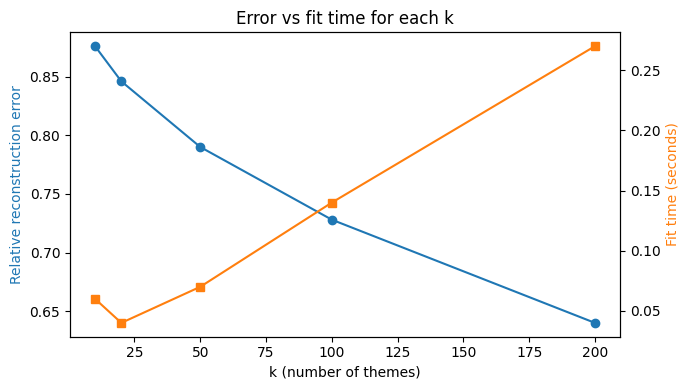

In [35]:
#error vs time tradeoff for each k for more informed decision

fig, ax_error = plt.subplots(figsize=(7, 4))
ax_time = ax_error.twinx()                                          # second y-axis on the right, same k axis

ax_error.plot(results["k"], results["error"], marker="o", color="tab:blue", label="Error (what we lose)")
ax_time.plot(results["k"], results["fit_seconds"], marker="s", color="tab:orange", label="Fit time (seconds)")

ax_error.set_xlabel("k (number of themes)")
ax_error.set_ylabel("Relative reconstruction error", color="tab:blue")
ax_time.set_ylabel("Fit time (seconds)", color="tab:orange")
ax_error.set_title("Error vs fit time for each k")                                     
plt.tight_layout(); plt.show()

Error goes down steadily with no clear flattening. Every extra theme still helps a little overall. Timing for any k stays under 0.3 seconds, which is very good, and we wouldn't consider it a constraint - all k fit fast. So we chose k = 100 as a balance between what we lose (error 0.73) and what we store and we will confirm it with the hit rate in ML4.

#### ML3